# Methods

## Dataset assembly and quality control

Publicly available microbiome amplicon-sequencing datasets of the human oral cavity were aggregated into a single global feature table, stored in BIOM format, together with harmonised per-sample metadata. Samples were quality-controlled and de-duplicated prior to analysis. Each sample was annotated with its study of origin (NCBI BioProject accession), health status, anatomical sampling site, and geographic region (continent group). Features were annotated against the Greengenes2 reference taxonomy.

## Sample and cohort selection

Analyses were restricted to healthy-control (HC) samples, identified from the curated `status_cleaned` field. HC samples were stratified by oral sampling site (`saliva`, `oral swab`, `oral mucosa`, and `tooth`); the co-occurrence analysis reported here focuses on the saliva site. Because microbial correlation networks were estimated within each study, only studies (BioProjects) contributing more than 50 HC samples at a given site were retained, ensuring that per-cohort correlation estimates were reasonably stable. Applying this criterion to saliva yielded 41 independent cohorts, which constitute the cohort set used in all downstream integration steps.

## Per-cohort co-occurrence networks

For each retained cohort, a taxon–taxon co-occurrence network was estimated using SparCC (ref XXX), which infers correlations between the abundances of features while explicitly accounting for the compositional nature of sequencing data. Each cohort *k* therefore contributed a symmetric correlation matrix $r^{(k)}$ defined over the taxa detected in that cohort. Per-cohort SparCC matrices were computed in advance and stored per study.

## Cross-cohort network integration

Per-cohort networks were integrated into a single consensus network following the meta-analytic strategy of NetMoss (Xiao et al., *Nature Computational Science*, 2022). Taxa were first aligned onto the union of all features observed across cohorts. For each taxon pair $(i, j)$, the cohort-specific correlations were combined by a fixed-effect, inverse-variance-weighted average:

$$
\bar r_{ij} \;=\; \frac{\sum_k w_{ij}^{(k)}\, r_{ij}^{(k)}}{\sum_k w_{ij}^{(k)}},
\qquad
w_{ij}^{(k)} \;=\; \frac{n_k - 1}{1 - \big(r_{ij}^{(k)}\big)^{2}},
$$

where $n_k$ is the sample size of cohort *k*, so that larger cohorts and stronger correlations receive proportionally greater weight. To ensure numerical stability, the denominator was clipped at a lower bound of $\varepsilon = 10^{-8}$, which prevents weight divergence as $|r| \to 1$; self-correlations (the matrix diagonal) were fixed to 1.

Two pooling variants were computed:

- **Zero-padded (consensus) variant.** A cohort that did not observe a given pair (i.e., at least one of the two taxa was absent from that cohort) was treated as reporting $r^{(k)}_{ij} = 0$ with weight $w^{(k)}_{ij} = n_k - 1$, following the NetMoss convention. Under this rule, missing evidence contributes to the denominator but not to the numerator, so pairs that are co-observed in only a few cohorts are shrunk toward zero and pairs never co-observed collapse to exactly zero. This variant was used as the global consensus matrix and as the reference for edge sign.

- **Observation-conditional variant.** Because zero-padding attenuates the magnitude of sparsely observed—but potentially genuine—associations, a second pooled correlation was computed over only those cohorts in which a pair was actually observed (no zero-padding). This observation-conditional estimate reflects the true association strength among co-observing cohorts and was used as the edge weight when constructing the consensus backbone (below). Zero-padding shrinks magnitude but does not flip sign, so the sign of the two variants is concordant.

## Edge reproducibility and consensus backbone

To distinguish reproducible associations from cohort-specific noise, each taxon pair was characterised by three quantities computed across the full cohort set. **Coverage** ($c_{ij}$) is the number of cohorts in which both taxa are present. An edge was deemed to be *confirmed* in a cohort when its correlation exceeded a per-cohort strength threshold ($|r^{(k)}_{ij}| \ge \tau_r$, with $\tau_r = 0.20$, used as a proxy for per-cohort significance) and its sign matched the pooled consensus sign. The **reproducibility rate** was then defined as $\rho_{ij} = (\text{number of confirming cohorts}) / c_{ij}$.

The high-confidence **consensus backbone** was constructed by retaining only edges that simultaneously satisfied: (i) coverage $c_{ij} \ge 5$ cohorts; (ii) reproducibility $\rho_{ij} \ge 0.60$; and (iii) an observation-conditional pooled magnitude $|\bar r_{ij}| \ge 0.20$. Retained edges were signed (positive/negative) according to the pooled correlation and assembled into an undirected weighted graph. For comparison, the network derived from the single largest cohort (thresholded at the same $|r| \ge \tau_r$) was visualised alongside the consensus backbone on a shared node layout, illustrating that single-cohort networks are dense and noisy whereas the integrated backbone retains only reproducible edges.

## Cohort-scale saturation analysis

To assess how the number of reliably placed edges depends on the number of integrated cohorts, a rarefaction-style saturation analysis was performed. For each subset size $K = 1, \dots, 41$, cohorts were added sequentially in random order and the number of edges passing the identical backbone criteria (coverage $\ge 5$, reproducibility $\ge 0.60$, $|\bar r| \ge 0.20$) was recorded. This procedure was repeated over 20 independent random permutations, accumulating cohorts along nested prefixes so that each $K$ yielded 20 independent samples. The mean and 5th–95th percentile envelope of the reproducible-edge count were plotted against $K$.

## Universal versus region-specific edges

To determine which associations are geographically conserved, cohorts were assigned to a geographic region using the majority `continent_group` label of their samples. Regions represented by at least 3 cohorts were considered qualifying. Within each qualifying region, the coverage, observation-conditional pooled correlation, and region-local reproducibility were recomputed, and a pair was considered *present* in that region when it satisfied a region-specific coverage cutoff of $\max(3, \lceil 0.5\, n_{\text{region}} \rceil)$ cohorts, reproducibility $\ge 0.60$, and $|\bar r| \ge 0.20$. Each edge present in at least one qualifying region was then classified as **core** (present in all qualifying regions), **region-specific** (present in exactly one region), or **shared** (present in more than one but not all regions). Edges whose pooled correlation changed sign across regions were additionally flagged as sign-conflicting. This classification identifies a globally conserved core of oral microbial interactions and distinguishes it from associations that are restricted to particular regions, populations, or sequencing contexts.

# **Global co-occurrence network of healthy oral (salivary) microbiomes**

This notebook integrates the per-study microbial correlation networks of many
independent oral-microbiome cohorts into a single consensus network, following
the network-integration idea of **NetMoss** (Xiao et al., *Nature Computational
Science*, 2022).

**Workflow**

1. Load the global oral feature (BIOM) table and its sample metadata.
2. Keep only healthy-control (**HC**) samples and split them by body site
   (saliva, oral swab, oral mucosa, tooth).
3. For each body site, keep the BioProjects (studies) with a sufficient sample
   size (**> 50 samples**) so that per-study correlations are reasonably estimable.
4. For each retained study a SparCC correlation matrix was computed beforehand and
   stored at `sparcc_hc_saliva/<bioproject_id>.csv`.
5. Pool these per-study matrices into one combined matrix using an
   **inverse-variance-weighted meta-analysis** of the correlation coefficients.
6. Inspect the distribution of the pooled correlations.

The run below is for the **saliva** site.

**1. Reproducibility.** Single-cohort SparCC networks are extremely noisy at small n and contradict each other across studies. Our contribution is to identify edges that are reproducible across many cohorts, assigning each edge a reproducibility rate — "the fraction of cohorts in which it is same-sign and significant." Presentation: place side by side the network from the single largest cohort and the integrated consensus backbone (clean, high-confidence), then show the reproducibility distribution. This demonstrates that without a large database these edges carry no credibility.

**2. Scale saturation curve.** X-axis = number of cohorts included (from 1 up to 41); Y-axis = number of reproducible edges that can be stably placed in the network. As cohorts are added, we show how the count of reliable edges grows and where it begins to saturate. This directly proves that our database reaches a scale threshold unattainable by any single study — scale buys robustness.

**3. Universal vs specific.** Split the edges into "globally conserved core edges" and "region-/population-/sequencing-platform-specific edges." With coverage spanning multiple countries, primers, and platforms, we can answer which oral microbial interactions are universal across humanity and which are regional.

In [152]:
import biom
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

## 1. Load data

Load the quality-controlled, de-duplicated sample metadata and the matching
feature (BIOM) table for the global oral microbiome dataset.

In [140]:
metadata = pd.read_csv("../../data/metadata-and-biom-v2-qc/metadata_oral_qc_dedup.tsv", sep="\t", low_memory=False)
table = biom.load_table("../../data/metadata-and-biom-v2-qc/biom_oral_qc_dedup.biom")

In [141]:
metadata.shape

(44446, 49)

In [142]:
table

61235 x 44446 <class 'biom.table.Table'> with 4724959 nonzero entries (0% dense)

In [143]:
metadata.head()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,site_cleaned,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
0,CNP0002325,B1,B1,1.8,852,125752,0.560900,0.748847,319,5.188369,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
1,CNP0002325,B3,B3,2.2,913,136072,0.540071,0.748847,330,5.245999,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
2,CNP0002325,B4,B4,0.7,444,163914,0.775532,0.748847,209,3.986967,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
3,CNP0002325,B5,B5,2.4,833,133478,0.560014,0.748847,306,5.078915,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no
4,CNP0002325,B6,B6,4.9,1371,210064,0.521746,0.748847,455,5.291183,...,tooth,Oral,Yes,Dental Caries,no,no,no,no,no,no


In [144]:
metadata.columns

Index(['bioproject_id', 'sample_id', 'subject_id', 'chim_perc', 'asv_count',
       'total_reads', 'sample_cr_mapping_rate', 'study_cr_mapping_rate',
       'Observed', 'Shannon', 'Simpson', 'InvSimpson', 'Chao1', 'age',
       'age_info', 'bmi', 'sex', 'platform', 'sequencing_region',
       'pcr_primers', 'country', 'site', 'site_group', 'disease_study',
       'status', 'title', 'public_time', 'matched_samples', 'is_time_series',
       'age_cleaned', 'bmi_cleaned', 'age_cleaned_group', 'age_info_cleaned',
       'bmi_cleaned_group', 'sex_cleaned', 'platform_cleaned',
       'sequencing_region_cleaned', 'country_cleaned', 'continent_group',
       'site_cleaned', 'site_group_cleaned', 'disease_study_cleaned',
       'status_cleaned', 'asv_le_30', 'study_asv_lt30_high', 'chim_gt_25',
       'study_chim_gt25_high', 'sample_cr_mapping_low',
       'study_cr_mapping_low'],
      dtype='object')

In [169]:
metadata.continent_group.unique()

array(['Asia', nan, 'North America', 'Europe', 'South America', 'Africa',
       'Oceania'], dtype=object)

In [94]:
metadata.status_cleaned.unique()

array(['Dental Caries', 'OSCC', 'HC', 'Gastroesophageal Reflux Disease',
       'IBD', 'Hypertension', nan, 'Other', 'Digestive Tract Cancer',
       'HIV', 'Diabetes', 'Clostridium Difficile Infection',
       'ICU discharge or on ICU day 10', 'ICU', 'Obesity', 'Asthma',
       'Periodontal Disease', 'Atopic Dermatitis',
       'Cardiovascular Disease', 'Chagas Disease', 'Head and Neck Cancer',
       'Oral Submucous Fibrosis', 'Oral Mucositis',
       'Oral Verrucous Hyperplasia', 'Preterm', 'Breast Cancer',
       'COVID-19', 'Prostate Cancer', 'Colorectal Cancer', 'Aphthous',
       'Oral Lichen Planus', 'Celiac Disease', 'Acute Myeloid Leukemia',
       'Lung Cancer', "Sjögren's Syndrome",
       'Helicobacter pylori Infection', 'Pancreatic Cancer',
       'Autoimmune Hepatitis', 'RA', 'Alcohol Use Disorder',
       'Esophageal Cancer', 'Hand, Foot and Mouth Disease',
       "Parkinson's Disease", '1-year COVID-19 convalescent',
       'COVID-19 discharge', 'Nonmalignant Breast Di

## 2. Restrict to healthy-control samples

Keep only samples labelled `HC` in `status_cleaned`, then inspect how the healthy
samples are distributed across body sites (`site_cleaned`).

In [95]:
metadata_hc = metadata.loc[metadata.status_cleaned == "HC"]

In [96]:
metadata_hc.groupby(["site_cleaned"]).count()

,bioproject_id,sample_id,subject_id,chim_perc,asv_count,total_reads,sample_cr_mapping_rate,study_cr_mapping_rate,Observed,Shannon,...,continent_group,site_group_cleaned,disease_study_cleaned,status_cleaned,asv_le_30,study_asv_lt30_high,chim_gt_25,study_chim_gt25_high,sample_cr_mapping_low,study_cr_mapping_low
site_cleaned,,,,,,,,,,,,,,,,,,,,,
gingiva,245,245,245,245,245,245,245,245,245,245,...,245,245,245,245,245,245,245,245,245,245
oral mucosa,1880,1880,1880,1880,1880,1880,1880,1880,1880,1880,...,1880,1880,1880,1880,1880,1880,1880,1880,1880,1880
oral swab,2516,2516,2516,2516,2516,2516,2516,2516,2516,2516,...,2516,2516,2516,2516,2516,2516,2516,2516,2516,2516
other,1321,1321,1321,1321,1321,1321,1321,1321,1321,1321,...,1130,1321,1271,1321,1321,1321,1321,1321,1321,1321
saliva,16143,16143,16143,16143,16143,16143,16143,16143,16143,16143,...,16067,16143,16143,16143,16143,16143,16143,16143,16143,16143
tongue,1127,1127,1127,1127,1127,1127,1127,1127,1127,1127,...,1127,1127,1127,1127,1127,1127,1127,1127,1127,1127
tooth,1734,1734,1734,1734,1734,1734,1734,1734,1734,1734,...,1734,1734,1734,1734,1734,1734,1734,1734,1734,1734


## 3. Select studies per body site

Correlation networks are estimated **within each study (BioProject)**, so a study
needs enough samples for the estimates to be stable. For each body site we group
the HC samples by `bioproject_id` and keep only studies with **more than 50
samples**. The same selection is applied to saliva, oral swab, oral mucosa and
tooth; the network integration below uses the **saliva** studies.

In [99]:
metadata_hc_saliva = metadata_hc.loc[metadata_hc.site_cleaned == "saliva"]
sample_counts = metadata_hc_saliva.groupby(["bioproject_id"]).count().sample_id.values
study_list = metadata_hc_saliva.bioproject_id.unique()
study_list = study_list[sample_counts > 50]

In [100]:
len(study_list)

41

In [101]:
study_list

array(['PRJCA005537', 'PRJDB8324', 'PRJEB20889', 'PRJEB20890',
       'PRJEB20894', 'PRJEB28088', 'PRJEB30836', 'PRJEB34215',
       'PRJEB35824', 'PRJEB36081', 'PRJEB37445', 'PRJEB38175',
       'PRJEB42371', 'PRJEB50306', 'PRJEB62655', 'PRJNA281060',
       'PRJNA386665', 'PRJNA427101', 'PRJNA434300', 'PRJNA434312',
       'PRJNA48333', 'PRJNA549488', 'PRJNA557511', 'PRJNA575550',
       'PRJNA575641', 'PRJNA613363', 'PRJNA674379', 'PRJNA689848',
       'PRJNA720269', 'PRJNA721325', 'PRJNA739492', 'PRJNA744870',
       'PRJNA767189', 'PRJNA778006', 'PRJNA778070', 'PRJNA801882',
       'PRJNA834584', 'PRJNA844909', 'PRJNA900274', 'PRJNA979793',
       'PRJNA997934'], dtype=object)

In [102]:
with open("study_list_saliva.txt", "w", encoding="utf-8") as f:
    for item in study_list:
        f.write(item + "\n")

In [103]:
metadata_hc_saliva = metadata_hc_saliva.loc[[i in study_list for i in metadata_hc_saliva.bioproject_id.values]]
metadata_hc_saliva.to_csv("../data/network/metadata_hc_saliva.csv", index=None)

In [105]:
metadata_hc_oral_swab = metadata_hc.loc[metadata_hc.site_cleaned == "oral swab"]
sample_counts = metadata_hc_oral_swab.groupby(["bioproject_id"]).count().sample_id.values
study_list = metadata_hc_oral_swab.bioproject_id.unique()
study_list = study_list[sample_counts > 50]
len(study_list)

4

In [106]:
metadata_hc_oral_mucosa = metadata_hc.loc[metadata_hc.site_cleaned == "oral mucosa"]
sample_counts = metadata_hc_oral_mucosa.groupby(["bioproject_id"]).count().sample_id.values
study_list = metadata_hc_oral_mucosa.bioproject_id.unique()
study_list = study_list[sample_counts > 50]
len(study_list)

7

In [107]:
metadata_hc_tooth = metadata_hc.loc[metadata_hc.site_cleaned == "tooth"]
sample_counts = metadata_hc_tooth.groupby(["bioproject_id"]).count().sample_id.values
study_list = metadata_hc_tooth.bioproject_id.unique()
study_list = study_list[sample_counts > 50]
len(study_list)

7

## 4. Integrate the per-study networks (NetMoss-style pooling)

Each retained study already has a SparCC correlation matrix
(`sparcc_hc_saliva/<bioproject_id>.csv`). Because different studies cover
different subsets of taxa, we first take the **union of all taxa** across studies
(`fid_all`) and align every study onto this shared feature space.

For each taxon pair *(i, j)* the per-study correlations $r_k$ are combined with an
**inverse-variance-weighted average** (a fixed-effect meta-analysis), exactly as
in the `getNetwork` step of NetMoss:

$$
\bar r_{ij} \;=\; \frac{\sum_k w_k\, r_{k}}{\sum_k w_k},
\qquad
w_k \;=\; \frac{n_k - 1}{1 - r_{k}^{2}},
$$

where $n_k$ is the sample size of study *k*, so larger studies and stronger
correlations receive more weight.

**Taxa missing from a study.** If a pair *(i, j)* is not observed in study *k*
(at least one of the two taxa is absent from that study), the study is treated as
reporting $r_k = 0$ with weight $w_k = n_k - 1$ (i.e. substituting $r = 0$ into the
weight formula). This is NetMoss's zero-padding behaviour: missing evidence pulls
the pooled correlation toward 0 instead of being ignored.

**Implementation**

- `w_sum_table` accumulates $\sum_k w_k$ and `wr_sum_table` accumulates
  $\sum_k w_k r_k$; the final matrix is their element-wise ratio
  `wr_sum_table / w_sum_table`.
- For each study, the observed block is filled with the real weights, and every
  block touching a missing taxon is filled with `weight_for_missing = n - 1`
  (numerator contribution 0).
- The diagonal is reset to 1 at the end (self-correlation).
- A small `eps` clips the denominator so that $|r| \to 1$ cannot produce infinite
  weights.

### Based on OTU table

In [145]:
study_list = metadata_hc_saliva.bioproject_id.unique()

In [146]:
fid_all = []
for i in study_list:
    cor_df = pd.read_csv(f"../data/network/sparcc_hc_saliva/{i}.csv", index_col=0)
    fid_all = fid_all + cor_df.index.to_list()

In [147]:
fid_all = np.unique(fid_all)

In [148]:
sid_all = metadata_hc_saliva.index.values

In [149]:
# fix #3: ensure fid_all is str so it matches the str-cast sparcc labels below;
#         otherwise np.intersect1d silently returns an empty intersection on int/str mismatch
fid_all = np.array([str(x) for x in fid_all])

eps = 1e-8  # fix #5: guard against |r|->1 where (1-r^2)=0 blows the weight up to inf

def fill_diag_safe(df, val):
    # newer numpy returns a read-only .values for DataFrame arithmetic results,
    # so np.fill_diagonal on it raises; write into a copy instead
    a = df.to_numpy(copy=True)
    np.fill_diagonal(a, val)
    return pd.DataFrame(a, index=df.index, columns=df.columns)

w_sum_table  = pd.DataFrame(np.zeros((len(fid_all), len(fid_all))), index=fid_all, columns=fid_all)
wr_sum_table = pd.DataFrame(np.zeros((len(fid_all), len(fid_all))), index=fid_all, columns=fid_all)

for i in study_list:
    sparcc = pd.read_csv(f"../data/network/sparcc_hc_saliva/{i}.csv", sep=",", index_col=0)

    # fix #6: use x instead of i so the comprehension no longer shadows the loop variable
    sparcc.index   = [str(x) for x in sparcc.index]
    sparcc.columns = [str(x) for x in sparcc.columns]

    inter_fid = np.intersect1d(sparcc.index.values, fid_all)
    sparcc = sparcc.loc[inter_fid, inter_fid]

    tmp = metadata_hc_saliva.loc[metadata_hc_saliva.bioproject_id == i]   # (#1 left unchanged)
    n = tmp.shape[0]
    # fix #2: n must be the sample count used to build this study's SparCC network;
    #         n < 2 makes the weights meaningless / negative
    assert n > 1, f"study {i}: n={n}, check that the metadata filter matches the network-building sample set"

    wr_sum_table_temp = pd.DataFrame(np.zeros((len(fid_all), len(fid_all))), index=fid_all, columns=fid_all)
    w_sum_table_temp  = pd.DataFrame(np.zeros((len(fid_all), len(fid_all))), index=fid_all, columns=fid_all)

    # fix #5: clip the denominator to eps; equivalent to (n-1)/(1-r^2) but robust when |r|~1
    w = (n - 1) / (1 - sparcc ** 2).clip(lower=eps)
    w = fill_diag_safe(w, 1)          # (write back into a writable copy)
    wr = w.mul(sparcc)

    w_sum_table_temp.loc[sparcc.index, sparcc.columns]  = w
    wr_sum_table_temp.loc[sparcc.index, sparcc.columns] = wr

    weight_for_missing = n - 1

    fid_not_in = pd.Index(fid_all).difference(sparcc.index)

    if not fid_not_in.empty:
        w_sum_table_temp.loc[sparcc.index, fid_not_in]  = weight_for_missing
        w_sum_table_temp.loc[fid_not_in, sparcc.columns] = weight_for_missing
        w_sum_table_temp.loc[fid_not_in, fid_not_in]     = weight_for_missing

    wr_sum_table = wr_sum_table + wr_sum_table_temp
    w_sum_table  = w_sum_table  + w_sum_table_temp

sparcc_combine = wr_sum_table / w_sum_table
sparcc_combine = fill_diag_safe(sparcc_combine, 1)   # fix #4: pooling pollutes the diagonal, reset it to 1

In [150]:
sparcc_combine

,AABF01000111,AB018439,AB021366,AB022925,AB023427,AB023968,AB027362.1.1386,AB035459,AB037874,AB037875,...,X94229,X95459,Y07841,Y09959,Y13364,Y13365,Y13672,Y15011,Y17280,Z97069
AABF01000111,1.000000,-0.000666,0.0,0.000000,0.000000,0.000578,0.000000,-0.001443,-0.000251,-0.005579,...,-0.001378,0.0,0.000000,-0.001352,0.00000,0.000180,0.000000,0.000000,0.000000,0.0
AB018439,-0.000666,1.000000,0.0,0.007774,0.000516,0.000000,0.000000,0.007361,0.000000,-0.020194,...,0.003741,0.0,0.009454,-0.000102,0.00000,0.006669,0.001305,0.000583,0.006413,0.0
AB021366,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,-0.001900,0.000000,...,0.000000,0.0,0.000000,0.000000,-0.00146,0.000000,0.000000,0.000000,0.000000,0.0
AB022925,0.000000,0.007774,0.0,1.000000,0.000000,0.000000,0.000000,0.010986,0.000000,-0.011973,...,0.000000,0.0,0.006497,-0.001641,0.00000,0.006021,0.000000,0.000000,0.007073,0.0
AB023427,0.000000,0.000516,0.0,0.000000,1.000000,0.000000,0.000000,-0.000344,0.000000,-0.001984,...,0.000000,0.0,0.000000,-0.000095,0.00000,0.000000,0.000538,0.000506,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y13365,0.000180,0.006669,0.0,0.006021,0.000000,0.000000,0.000983,0.004630,0.000114,-0.020015,...,0.000000,0.0,0.006363,0.000747,0.00000,1.000000,0.000000,0.000000,0.005565,0.0
Y13672,0.000000,0.001305,0.0,0.000000,0.000538,0.000000,0.000000,0.000220,0.000000,-0.003445,...,0.000000,0.0,0.000000,-0.000374,0.00000,0.000000,1.000000,0.002019,0.000000,0.0
Y15011,0.000000,0.000583,0.0,0.000000,0.000506,0.000000,0.000000,0.001212,0.000000,-0.004009,...,0.000000,0.0,0.000000,0.000078,0.00000,0.000000,0.002019,1.000000,0.000000,0.0
Y17280,0.000000,0.006413,0.0,0.007073,0.000000,0.000000,0.000000,0.005464,0.000000,-0.013416,...,0.000000,0.0,0.006803,-0.002068,0.00000,0.005565,0.000000,0.000000,1.000000,0.0


## 5. Distribution of the pooled correlations

Histogram of the upper-triangle (off-diagonal) entries of the combined matrix,
with the mean and median marked.

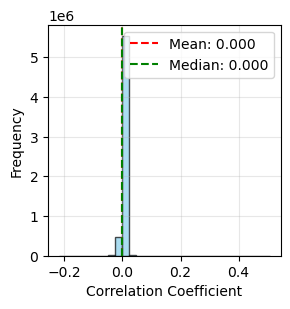

Mean: 0.0000
Median: 0.0000
cor range: [-0.2192, 0.5083]


In [151]:
def plot_upper_triangle_hist(df_corr):

    upper_triangle = df_corr.where(np.triu(np.ones(df_corr.shape), k=1).astype(bool))
    corr_values = upper_triangle.stack().values
    
    plt.figure(figsize=(3, 3))
    plt.hist(corr_values, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
    plt.xlabel('Correlation Coefficient')
    plt.ylabel('Frequency')
    plt.grid(alpha=0.3)
    
    mean_val = np.mean(corr_values)
    median_val = np.median(corr_values)
    plt.axvline(mean_val, color='red', linestyle='--', label=f'Mean: {mean_val:.3f}')
    plt.axvline(median_val, color='green', linestyle='--', label=f'Median: {median_val:.3f}')
    plt.legend()
    
    plt.show()
    
    print(f"Mean: {mean_val:.4f}")
    print(f"Median: {median_val:.4f}")
    print(f"cor range: [{np.min(corr_values):.4f}, {np.max(corr_values):.4f}]")

plot_upper_triangle_hist(sparcc_combine)

## 6. Why are most pooled correlations close to zero?

The sharp peak at 0 is driven by **feature sparsity**, not by a genuine absence of
microbial associations.

Each study contains only a small fraction of the thousands of taxa in the global
union `fid_all`, so **most taxon pairs are co-observed in only a few studies, or
in none at all**. Under the pooling rule above, every study that is *missing* a
pair still adds a term to the denominator ($w_k = n_k - 1$) while contributing 0
to the numerator. As the number of missing studies grows, this "missing-as-zero"
penalty in the denominator grows with it, so:

- pairs that are **never co-observed** collapse to exactly 0 (this means *no
  data*, not *no correlation*), and
- pairs seen in **only a few studies** are strongly **shrunk toward 0**, because
  the many absent studies dominate the weighted average.

In short, the sparser a pair is across cohorts, the larger the shrinkage penalty
the algorithm applies — which is why the pooled distribution piles up near zero
even though real associations exist (the observed range is roughly
$[-0.22,\ 0.51]$). Restricting to pairs with sufficient cross-study coverage would
expose the true signal that is currently hidden under this peak.

In [154]:
# ----------------------------- parameters (tune) -----------------------------
SPARCC_DIR    = "../data/network/sparcc_hc_saliva"
R_THR         = 0.20   # per-cohort "strong edge" magnitude; proxy for significance.
                       # If you have per-cohort bootstrap p-values, swap this test
                       # for (p < 0.05) inside _cohort_strong().
K_MIN         = 5      # a pair must be co-observed in >= K_MIN cohorts to be judged
REPRO_THR     = 0.60   # min reproducibility rate to enter the backbone
CONSENSUS_THR = 0.20   # min |pooled r| (from sparcc_combine) to enter the backbone
BIOPROJECT_COL = "bioproject_id"

In [161]:
# ----------------------------- core computation ------------------------------
def _load_cohort(sid, fid_all, sparcc_dir):
    """Load one cohort's SparCC matrix, align labels to str, intersect with fid_all."""
    s = pd.read_csv(f"{sparcc_dir}/{sid}.csv", sep=",", index_col=0)
    s.index = [str(x) for x in s.index]
    s.columns = [str(x) for x in s.columns]
    inter = np.intersect1d(s.index.values, fid_all)
    if len(inter) < 2:
        return None, None
    return s.loc[inter, inter], inter


def build_edge_stats(study_list, metadata, fid_all, sparcc_combine,
                     sparcc_dir=SPARCC_DIR, r_thr=R_THR,
                     bioproject_col=BIOPROJECT_COL, eps=1e-8):
    """
    Accumulate, for every taxon pair (aligned to fid_all):
      coverage   : # cohorts that co-observe the pair
      n_confirm  : # cohorts where it is strong AND same-sign as the pooled estimate
      repro      : n_confirm / coverage                      (NaN where coverage == 0)
      pooled_obs : inverse-variance weighted r pooled ONLY over cohorts that observed
                   the pair (no zero-padding), i.e. the real association strength.
                   This avoids the sparsity-driven shrinkage of the zero-padded
                   `sparcc_combine`, so it is the right weight for a backbone.

    `sparcc_combine` is used only as the sign reference for "same-sign" (its sign
    equals that of pooled_obs; zero-padding shrinks magnitude but never flips sign).
    """
    fid_all = np.asarray([str(x) for x in fid_all])
    N = len(fid_all)
    pos = {f: k for k, f in enumerate(fid_all)}
    n_by_study = metadata[bioproject_col].value_counts()

    coverage  = np.zeros((N, N), dtype=np.int32)
    n_confirm = np.zeros((N, N), dtype=np.int32)
    w_obs     = np.zeros((N, N), dtype=np.float64)   # sum of weights,  observed only
    wr_obs    = np.zeros((N, N), dtype=np.float64)   # sum of weight*r, observed only

    cons_sign = np.sign(
        sparcc_combine.reindex(index=fid_all, columns=fid_all).values
    ).astype(np.float32)

    for sid in study_list:
        s, inter = _load_cohort(sid, fid_all, sparcc_dir)
        if s is None:
            continue
        n = int(n_by_study.get(sid, 0))
        if n < 2:
            continue
        idx = np.fromiter((pos[f] for f in inter), dtype=np.int64, count=len(inter))

        # pairs where BOTH taxa are present in this cohort
        present = np.zeros(N, dtype=bool)
        present[idx] = True
        obs = np.outer(present, present)
        coverage += obs

        # align this cohort's r into the full grid (0 where not observed)
        r_full = np.zeros((N, N), dtype=np.float32)
        r_full[np.ix_(idx, idx)] = s.values.astype(np.float32)

        # inverse-variance weights, restricted to the observed block
        w_blk = (n - 1) / np.clip(1.0 - s.values.astype(np.float64) ** 2, eps, None)
        w_full = np.zeros((N, N), dtype=np.float64)
        w_full[np.ix_(idx, idx)] = w_blk
        w_obs  += w_full
        wr_obs += w_full * r_full

        strong  = obs & (np.abs(r_full) >= r_thr)                             # "significant"
        confirm = strong & (np.sign(r_full) == cons_sign) & (cons_sign != 0)  # + same sign
        n_confirm += confirm

    with np.errstate(invalid="ignore", divide="ignore"):
        repro = np.where(coverage > 0, n_confirm / coverage, np.nan).astype(np.float32)
        pooled_obs = np.where(w_obs > 0, wr_obs / w_obs, np.nan).astype(np.float32)

    return coverage, n_confirm, repro, pooled_obs, fid_all


def build_backbone(pooled_obs, coverage, repro, fid_all,
                   k_min=K_MIN, repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR):
    """
    Filter into a high-confidence edge list + graph. Edge weight is the
    observation-conditional pooled r (`pooled_obs`), NOT the zero-padded value,
    so real edges are not shrunk away by sparsity.
    """
    fid_all = np.asarray([str(x) for x in fid_all])
    R = pooled_obs
    N = len(fid_all)
    iu = np.triu_indices(N, k=1)          # upper triangle, no diagonal

    r_u, cov_u, rep_u = R[iu], coverage[iu], repro[iu]
    keep = (
        (cov_u >= k_min)
        & (~np.isnan(rep_u)) & (rep_u >= repro_thr)
        & (~np.isnan(r_u)) & (np.abs(r_u) >= consensus_thr)
    )
    ii, jj = iu[0][keep], iu[1][keep]

    edges = pd.DataFrame({
        "taxon_i": fid_all[ii],
        "taxon_j": fid_all[jj],
        "r": r_u[keep],
        "coverage": cov_u[keep],
        "reproducibility": rep_u[keep],
    })
    edges = edges.reindex(edges.r.abs().sort_values(ascending=False).index).reset_index(drop=True)

    G = nx.Graph()
    for _, e in edges.iterrows():
        G.add_edge(e.taxon_i, e.taxon_j, weight=float(e.r), sign=int(np.sign(e.r)),
                   coverage=int(e.coverage), reproducibility=float(e.reproducibility))
    return edges, G


def largest_cohort_network(study_list, metadata, fid_all,
                           sparcc_dir=SPARCC_DIR, r_thr=R_THR,
                           bioproject_col=BIOPROJECT_COL):
    """Network of the single cohort with the most samples, thresholded at r_thr."""
    fid_all = np.asarray([str(x) for x in fid_all])
    counts = metadata[bioproject_col].value_counts()
    counts = counts[counts.index.isin(list(study_list))]
    top, n_top = counts.idxmax(), int(counts.max())

    s, inter = _load_cohort(top, fid_all, sparcc_dir)
    A = s.values
    iu = np.triu_indices(len(inter), k=1)
    r_u = A[iu]
    keep = np.abs(r_u) >= r_thr
    ii, jj = iu[0][keep], iu[1][keep]

    G = nx.Graph()
    for a, b, w in zip(inter[ii], inter[jj], r_u[keep]):
        G.add_edge(a, b, weight=float(w), sign=int(np.sign(w)))
    return top, n_top, G


# ------------------------------- visualization -------------------------------
def _subgraph_on_nodes(G, nodes):
    """Edges of G restricted to a fixed node set; keeps all nodes (even isolated)."""
    H = nx.Graph()
    H.add_nodes_from(nodes)
    for a, b, d in G.edges(data=True):
        if a in H and b in H:
            H.add_edge(a, b, **d)
    return H


def _draw_on(H, pos, ax, title, deg_ref):
    if H.number_of_nodes() == 0:
        ax.set_title(title + "\n(empty)"); ax.axis("off"); return
    ecol = ["#c0392b" if d["weight"] > 0 else "#2980b9" for *_, d in H.edges(data=True)]
    ew   = [0.25 + 2.0 * abs(d["weight"]) for *_, d in H.edges(data=True)]
    ns   = [8 + 10 * deg_ref.get(n, 0) for n in H.nodes()]   # size by backbone degree
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color=ecol, width=ew, alpha=0.35)
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=ns, node_color="#2c3e50", linewidths=0)
    ax.set_title(title); ax.axis("off")


def plot_comparison(G_single, single_label, G_consensus,
                    node_set="union", seed=42, savepath=None):
    """
    Both panels share the SAME nodes and the SAME coordinates (layout computed from
    the clean consensus backbone), so each taxon sits in the same spot on the left
    and right. That makes the contrast readable: identical points, but the single
    cohort is densely/noisily connected while the backbone keeps only reproducible
    edges.

    node_set : "union"    -> backbone nodes + the single cohort's nodes (fair view of
                             how much the single cohort adds/over-connects)
               "backbone" -> backbone nodes only (cleaner, focuses on kept taxa)
    """
    from matplotlib.lines import Line2D

    if node_set == "backbone":
        nodes = sorted(set(G_consensus.nodes()))
    else:
        nodes = sorted(set(G_consensus.nodes()) | set(G_single.nodes()))

    Hc = _subgraph_on_nodes(G_consensus, nodes)
    Hs = _subgraph_on_nodes(G_single, nodes)

    # one layout, driven by the backbone, reused for BOTH panels
    pos = nx.spring_layout(Hc, seed=seed, k=1.5 / np.sqrt(max(len(nodes), 1)),
                           iterations=200)
    deg_ref = dict(Hc.degree())

    fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
    _draw_on(Hs, pos, axes[0],
             f"Largest single cohort  ({single_label})\n"
             f"{Hs.number_of_nodes()} shared taxa, {Hs.number_of_edges()} edges",
             deg_ref)
    _draw_on(Hc, pos, axes[1],
             f"Integrated consensus backbone\n"
             f"{Hc.number_of_nodes()} taxa, {Hc.number_of_edges()} edges",
             deg_ref)
    fig.suptitle("Same taxa, same positions: the single cohort is dense and noisy; "
                 "the backbone keeps only reproducible edges", fontsize=12)
    axes[1].legend(handles=[Line2D([0],[0],color="#c0392b",lw=2,label="positive"),
                            Line2D([0],[0],color="#2980b9",lw=2,label="negative")],
                   loc="lower right", frameon=False)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig


def plot_reproducibility(repro, coverage, k_min=K_MIN, savepath=None):
    N = repro.shape[0]
    iu = np.triu_indices(N, k=1)
    rep_u, cov_u = repro[iu], coverage[iu]

    elig = (cov_u >= k_min) & (~np.isnan(rep_u))
    vals = rep_u[elig]

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(vals, bins=20, color="#7f8c8d", edgecolor="black")
    ax[0].axvline(np.median(vals), color="red", ls="--",
                  label=f"median = {np.median(vals):.2f}")
    ax[0].set_xlabel(f"Reproducibility rate  (pairs with coverage >= {k_min})")
    ax[0].set_ylabel("Number of pairs")
    ax[0].legend(frameon=False)

    # coverage histogram: shows why single/few cohorts cannot support confidence
    cov_pairs = cov_u[cov_u > 0]
    ax[1].hist(cov_pairs, bins=range(1, int(cov_pairs.max()) + 2),
               color="#95a5a6", edgecolor="black", align="left")
    ax[1].axvline(k_min - 0.5, color="red", ls="--", label=f"coverage cutoff = {k_min}")
    ax[1].set_xlabel("Coverage (# cohorts co-observing a pair)")
    ax[1].set_ylabel("Number of pairs")
    ax[1].legend(frameon=False)

    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig, vals


# ============================ scale saturation curve ============================
def _precompute_cohorts(study_list, metadata, fid_all, sparcc_dir, r_thr,
                        bioproject_col=BIOPROJECT_COL, eps=1e-8):
    """Load every cohort once into compact (idx, submatrix, weights) form."""
    fid_all = np.asarray([str(x) for x in fid_all])
    pos = {f: k for k, f in enumerate(fid_all)}
    n_by_study = metadata[bioproject_col].value_counts()
    packed = []
    for sid in study_list:
        s, inter = _load_cohort(sid, fid_all, sparcc_dir)
        if s is None:
            continue
        n = int(n_by_study.get(sid, 0))
        if n < 2:
            continue
        idx = np.fromiter((pos[f] for f in inter), dtype=np.int64, count=len(inter))
        sub = s.values.astype(np.float64)
        wblk = (n - 1) / np.clip(1.0 - sub ** 2, eps, None)
        packed.append((idx, sub, wblk))
    return packed, len(fid_all)


def saturation_curve(study_list, metadata, fid_all, sparcc_combine=None,
                     sparcc_dir=SPARCC_DIR, r_thr=R_THR, k_min=K_MIN,
                     repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
                     n_perm=20, seed=0, ks=None):
    """
    For K = 1..#cohorts, count how many edges pass the SAME backbone criteria
    (coverage >= k_min, reproducibility >= repro_thr, |pooled r| >= consensus_thr)
    when only K randomly-chosen cohorts are used.

    Each of `n_perm` random permutations is accumulated cohort-by-cohort (nested
    prefixes), giving n_perm independent samples per K. Sign for "same-sign" is the
    subset's own pooled sign, so no full-data information leaks into small-K points.

    Returns (Ks, counts) where counts has shape (n_perm, len(Ks)).
    """
    packed, N = _precompute_cohorts(study_list, metadata, fid_all, sparcc_dir, r_thr)
    n_studies = len(packed)
    if ks is None:
        ks = np.arange(1, n_studies + 1)
    ks = np.asarray(ks)
    kset = set(int(k) for k in ks)
    iu = np.triu_indices(N, k=1)

    counts = np.zeros((n_perm, len(ks)), dtype=np.int32)
    rng = np.random.default_rng(seed)

    for p in range(n_perm):
        order = rng.permutation(n_studies)
        coverage = np.zeros((N, N), dtype=np.int32)
        n_pos    = np.zeros((N, N), dtype=np.int32)
        n_neg    = np.zeros((N, N), dtype=np.int32)
        w        = np.zeros((N, N), dtype=np.float64)
        wr       = np.zeros((N, N), dtype=np.float64)

        col = 0
        for step, ci in enumerate(order, start=1):
            idx, sub, wblk = packed[ci]
            ix = np.ix_(idx, idx)
            coverage[ix] += 1
            n_pos[ix] += (sub >= r_thr)
            n_neg[ix] += (sub <= -r_thr)
            w[ix]  += wblk
            wr[ix] += wblk * sub

            if step in kset:
                cov_u = coverage[iu]; w_u = w[iu]; wr_u = wr[iu]
                np_u = n_pos[iu];     nn_u = n_neg[iu]
                with np.errstate(invalid="ignore", divide="ignore"):
                    pooled = wr_u / w_u
                    nconf  = np.where(wr_u > 0, np_u, nn_u)
                    repro  = np.where(cov_u > 0, nconf / cov_u, np.nan)
                keep = (
                    (cov_u >= k_min)
                    & (repro >= repro_thr)
                    & (np.abs(pooled) >= consensus_thr)
                )
                counts[p, col] = int(np.count_nonzero(keep))
                col += 1

    return ks, counts


def plot_saturation(ks, counts, savepath=None):
    mean = counts.mean(axis=0)
    lo = np.percentile(counts, 5, axis=0)
    hi = np.percentile(counts, 95, axis=0)
    full_ref = int(round(mean[-1]))            # K = all cohorts (identical across perms)

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.fill_between(ks, lo, hi, color="#2c3e50", alpha=0.15, label="5-95% over random subsets")
    ax.plot(ks, mean, color="#2c3e50", lw=2.2, label="mean")
    ax.axhline(full_ref, ls="--", color="#c0392b",
               label=f"all {int(ks[-1])} cohorts = {full_ref} edges")
    ax.scatter([ks[0]], [mean[0]], color="#c0392b", zorder=5)
    ax.annotate(f"K=1: {mean[0]:.0f}", (ks[0], mean[0]),
                textcoords="offset points", xytext=(8, 8), color="#c0392b")
    ax.set_xlabel("Number of cohorts included (K)")
    ax.set_ylabel("Reproducible backbone edges")
    ax.set_title("Reproducible edges grow with cohort count, then saturate\n"
                 "(single studies never reach this regime — scale buys robustness)")
    ax.legend(frameon=False, loc="lower right")
    ax.margins(x=0.01)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig, dict(mean=mean, lo=lo, hi=hi, full_ref=full_ref)

To distinguish reproducible associations from cohort-specific noise, each taxon pair was characterised by three quantities computed across the full cohort set. **Coverage** ($c_{ij}$) is the number of cohorts in which both taxa are present. An edge was deemed to be *confirmed* in a cohort when its correlation exceeded a per-cohort strength threshold ($|r^{(k)}_{ij}| \ge \tau_r$, with $\tau_r = 0.20$, used as a proxy for per-cohort significance) and its sign matched the pooled consensus sign. The **reproducibility rate** was then defined as $\rho_{ij} = (\text{number of confirming cohorts}) / c_{ij}$.

The high-confidence **consensus backbone** was constructed by retaining only edges that simultaneously satisfied: (i) coverage $c_{ij} \ge 5$ cohorts; (ii) reproducibility $\rho_{ij} \ge 0.60$; and (iii) an observation-conditional pooled magnitude $|\bar r_{ij}| \ge 0.20$. Retained edges were signed (positive/negative) according to the pooled correlation and assembled into an undirected weighted graph. For comparison, the network derived from the single largest cohort (thresholded at the same $|r| \ge \tau_r$) was visualised alongside the consensus backbone on a shared node layout, illustrating that single-cohort networks are dense and noisy whereas the integrated backbone retains only reproducible edges.

largest cohort            : PRJNA801882  (n=3388 samples)
  single-cohort edges     : 2,555  (|r| >= 0.2)
consensus backbone edges  : 552  (coverage>=5, repro>=0.6, |r|>=0.2)
  backbone taxa           : 166
  backbone median repro   : 0.71
  median repro (all pairs, coverage>=5) : 0.00


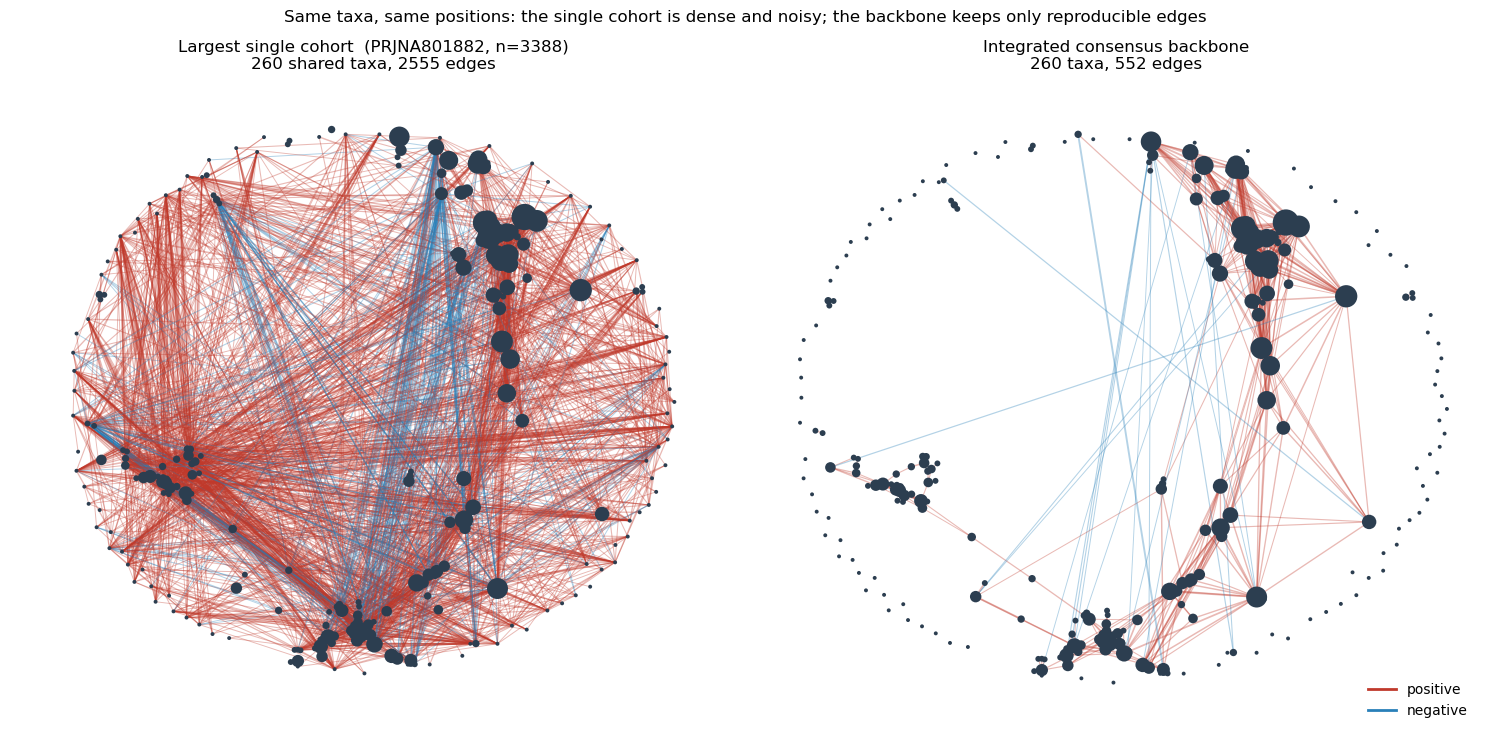

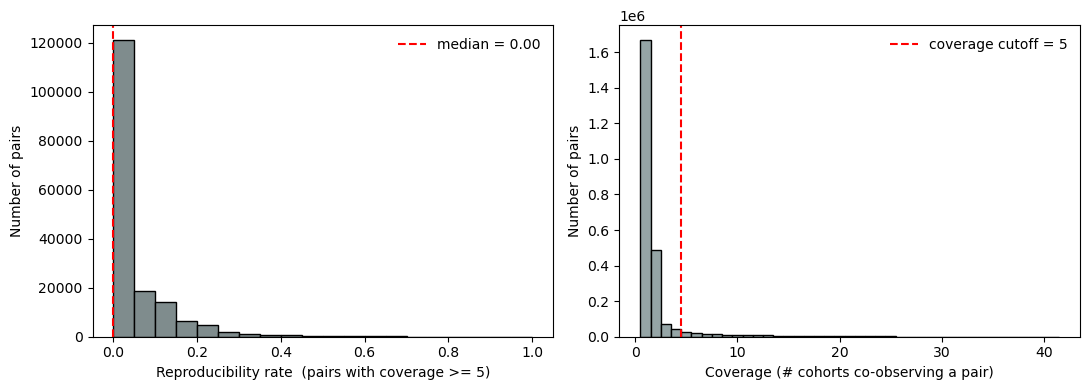

In [163]:
r_thr = R_THR
k_min = K_MIN
repro_thr = REPRO_THR 
consensus_thr = CONSENSUS_THR

coverage, n_confirm, repro, pooled_obs, fid_all = build_edge_stats(
    study_list, metadata_hc_saliva, fid_all, sparcc_combine)

edges, G_cons = build_backbone(
    pooled_obs, coverage, repro, fid_all)

top, n_top, G_single = largest_cohort_network(
    study_list, metadata_hc_saliva, fid_all)

node_set = "union"
save_prefix = ""
fig_net = plot_comparison(
    G_single, f"{top}, n={n_top}", G_cons, node_set=node_set,
    savepath=(f"{save_prefix}_networks.png" if save_prefix else None))
fig_rep, repro_vals = plot_reproducibility(
    repro, coverage, k_min,
    savepath=(f"{save_prefix}_reproducibility.png" if save_prefix else None))

print(f"largest cohort            : {top}  (n={n_top} samples)")
print(f"  single-cohort edges     : {G_single.number_of_edges():,}  "
      f"(|r| >= {r_thr})")
print(f"consensus backbone edges  : {G_cons.number_of_edges():,}  "
      f"(coverage>={k_min}, repro>={repro_thr}, |r|>={consensus_thr})")
print(f"  backbone taxa           : {G_cons.number_of_nodes():,}")
if len(edges):
    print(f"  backbone median repro   : {edges.reproducibility.median():.2f}")
print(f"  median repro (all pairs, coverage>={k_min}) : {np.nanmedian(repro_vals):.2f}")

In [164]:
# ----------------------------- parameters (tune) -----------------------------
SPARCC_DIR    = "../data/network/sparcc_hc_saliva"
R_THR         = 0.20   # per-cohort "strong edge" magnitude; proxy for significance.
                       # If you have per-cohort bootstrap p-values, swap this test
                       # for (p < 0.05) inside _cohort_strong().
K_MIN         = 5      # a pair must be co-observed in >= K_MIN cohorts to be judged
REPRO_THR     = 0.60   # min reproducibility rate to enter the backbone
CONSENSUS_THR = 0.20   # min |pooled r| (from sparcc_combine) to enter the backbone
BIOPROJECT_COL = "bioproject_id"

In [167]:
def saturation_curve(study_list, metadata, fid_all, sparcc_combine=None,
                     sparcc_dir=SPARCC_DIR, r_thr=R_THR, k_min=K_MIN,
                     repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
                     n_perm=20, seed=0, ks=None):
    """
    For K = 1..#cohorts, count how many edges pass the SAME backbone criteria
    (coverage >= k_min, reproducibility >= repro_thr, |pooled r| >= consensus_thr)
    when only K randomly-chosen cohorts are used.

    Each of `n_perm` random permutations is accumulated cohort-by-cohort (nested
    prefixes), giving n_perm independent samples per K. Sign for "same-sign" is the
    subset's own pooled sign, so no full-data information leaks into small-K points.

    Returns (Ks, counts) where counts has shape (n_perm, len(Ks)).
    """
    packed, N = _precompute_cohorts(study_list, metadata, fid_all, sparcc_dir, r_thr)
    n_studies = len(packed)
    if ks is None:
        ks = np.arange(1, n_studies + 1)
    ks = np.asarray(ks)
    kset = set(int(k) for k in ks)
    iu = np.triu_indices(N, k=1)

    counts = np.zeros((n_perm, len(ks)), dtype=np.int32)
    rng = np.random.default_rng(seed)

    for p in range(n_perm):
        order = rng.permutation(n_studies)
        coverage = np.zeros((N, N), dtype=np.int32)
        n_pos    = np.zeros((N, N), dtype=np.int32)
        n_neg    = np.zeros((N, N), dtype=np.int32)
        w        = np.zeros((N, N), dtype=np.float64)
        wr       = np.zeros((N, N), dtype=np.float64)

        col = 0
        for step, ci in enumerate(order, start=1):
            idx, sub, wblk = packed[ci]
            ix = np.ix_(idx, idx)
            coverage[ix] += 1
            n_pos[ix] += (sub >= r_thr)
            n_neg[ix] += (sub <= -r_thr)
            w[ix]  += wblk
            wr[ix] += wblk * sub

            if step in kset:
                cov_u = coverage[iu]; w_u = w[iu]; wr_u = wr[iu]
                np_u = n_pos[iu];     nn_u = n_neg[iu]
                with np.errstate(invalid="ignore", divide="ignore"):
                    pooled = wr_u / w_u
                    nconf  = np.where(wr_u > 0, np_u, nn_u)
                    repro  = np.where(cov_u > 0, nconf / cov_u, np.nan)
                keep = (
                    (cov_u >= k_min)
                    & (repro >= repro_thr)
                    & (np.abs(pooled) >= consensus_thr)
                )
                counts[p, col] = int(np.count_nonzero(keep))
                col += 1

    return ks, counts

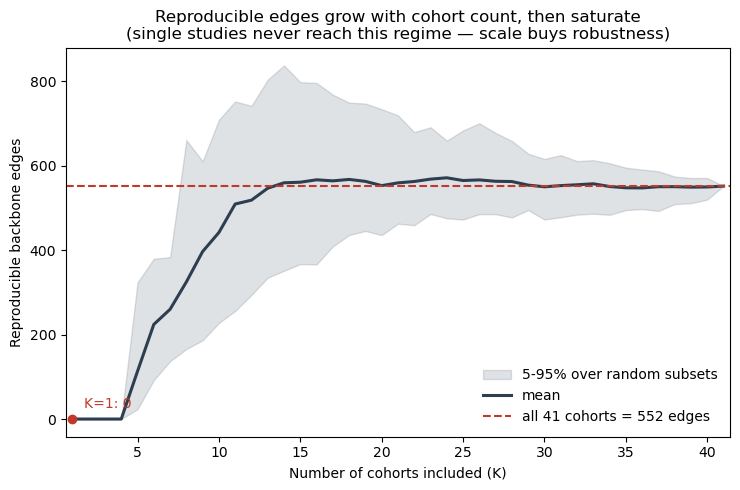

In [168]:
ks, counts = saturation_curve(
    study_list, metadata_hc_saliva, fid_all,
    sparcc_dir="../data/network/sparcc_hc_saliva",
    r_thr=0.20, k_min=5, repro_thr=0.60, consensus_thr=0.20,
    n_perm=20,      
    seed=0,
)
fig, stats = plot_saturation(ks, counts, savepath="saliva_saturation.png")

In [175]:
# ------------------------------ per-region stats -----------------------------
def _pack_by_study(study_list, metadata, fid_all, sparcc_dir,
                   bioproject_col="bioproject_id", eps=1e-8):
    """Load every cohort once -> {sid: (idx, submatrix, weights)} aligned to fid_all."""
    fid_all = np.asarray([str(x) for x in fid_all])
    pos = {f: k for k, f in enumerate(fid_all)}
    n_by_study = metadata[bioproject_col].value_counts()
    packed = {}
    for sid in study_list:
        s, inter = _load_cohort(sid, fid_all, sparcc_dir)
        if s is None:
            continue
        n = int(n_by_study.get(sid, 0))
        if n < 2:
            continue
        idx = np.fromiter((pos[f] for f in inter), dtype=np.int64, count=len(inter))
        sub = s.values.astype(np.float64)
        wblk = (n - 1) / np.clip(1.0 - sub ** 2, eps, None)
        packed[sid] = (idx, sub, wblk)
    return packed, len(fid_all)


def _stats_for(sids, packed, N, r_thr, eps=1e-8):
    """coverage, pooled r (observed-only), reproducibility (region-local sign)."""
    coverage = np.zeros((N, N), dtype=np.int32)
    n_pos    = np.zeros((N, N), dtype=np.int32)
    n_neg    = np.zeros((N, N), dtype=np.int32)
    w        = np.zeros((N, N), dtype=np.float64)
    wr       = np.zeros((N, N), dtype=np.float64)
    for sid in sids:
        if sid not in packed:
            continue
        idx, sub, wblk = packed[sid]
        ix = np.ix_(idx, idx)
        coverage[ix] += 1
        n_pos[ix] += (sub >= r_thr)
        n_neg[ix] += (sub <= -r_thr)
        w[ix]  += wblk
        wr[ix] += wblk * sub
    with np.errstate(invalid="ignore", divide="ignore"):
        pooled = np.where(w > 0, wr / w, np.nan)
        nconf  = np.where(wr > 0, n_pos, n_neg)
        repro  = np.where(coverage > 0, nconf / coverage, np.nan)
    return coverage, pooled, repro


# ------------------------------ classification -------------------------------
def classify_edges(study_list, metadata, fid_all,
                   sparcc_dir=SPARCC_DIR, region_col="continent_group",
                   min_studies_per_region=3,
                   r_thr=R_THR, repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
                   region_cov_min=3, region_cov_frac=0.5, core_frac=1.0):
    """
    Returns (edges_df, info).
      edges_df : one row per edge present in >= 1 qualifying region, with columns
                 taxon_i, taxon_j, n_present, regions_present, category,
                 sign_conflict, and r_<region> (pooled r; NaN where not present).
      info     : dict with the qualifying regions, cohort counts, and per-region
                 coverage cutoffs actually used.
    """
    fid_all = np.asarray([str(x) for x in fid_all])
    packed, N = _pack_by_study(study_list, metadata, fid_all, sparcc_dir)

    # cohort -> region (majority label per bioproject), then count cohorts per region
    reg_of = (metadata.groupby("bioproject_id")[region_col]
              .agg(lambda x: x.mode().iloc[0] if len(x.mode()) else np.nan))
    region_to_sids = {}
    for sid in packed:                                   # only cohorts with usable data
        r = reg_of.get(sid, np.nan)
        if pd.isna(r):
            continue
        region_to_sids.setdefault(r, []).append(sid)

    qualifying = {r: s for r, s in region_to_sids.items()
                  if len(s) >= min_studies_per_region}
    regions = sorted(qualifying)
    if len(regions) < 2:
        raise ValueError(f"need >= 2 qualifying regions (>= {min_studies_per_region} "
                         f"cohorts each); got {[(r, len(s)) for r, s in region_to_sids.items()]}")

    iu = np.triu_indices(N, k=1)
    presence, pooled_by_region, region_k_used = {}, {}, {}
    for r in regions:
        cov, pooled, repro = _stats_for(qualifying[r], packed, N, r_thr)
        n_r = len(qualifying[r])
        region_k = max(region_cov_min, int(np.ceil(region_cov_frac * n_r)))
        region_k_used[r] = region_k
        cov_u, pooled_u, repro_u = cov[iu], pooled[iu], repro[iu]
        present = (
            (cov_u >= region_k)
            & (repro_u >= repro_thr)
            & (~np.isnan(pooled_u)) & (np.abs(pooled_u) >= consensus_thr)
        )
        presence[r] = present
        pooled_by_region[r] = pooled_u

    P = np.column_stack([presence[r] for r in regions])          # (n_pairs, n_regions)
    R = np.column_stack([pooled_by_region[r] for r in regions])  # pooled r
    n_present = P.sum(axis=1)
    cand = n_present > 0
    ci, cj = iu[0][cand], iu[1][cand]
    Pc, Rc, npc = P[cand], R[cand], n_present[cand]

    n_regions = len(regions)
    core_min = int(np.ceil(core_frac * n_regions))

    rows = []
    for k in range(Pc.shape[0]):
        present_mask = Pc[k]
        present_regions = [regions[j] for j in range(n_regions) if present_mask[j]]
        signs = np.sign(Rc[k][present_mask])
        conflict = (np.any(signs > 0) and np.any(signs < 0))
        if npc[k] >= core_min:
            category = "core"
        elif npc[k] == 1:
            category = f"specific:{present_regions[0]}"
        else:
            category = "shared"
        row = {"taxon_i": fid_all[ci[k]], "taxon_j": fid_all[cj[k]],
               "n_present": int(npc[k]),
               "regions_present": ";".join(map(str, present_regions)),
               "category": category, "sign_conflict": bool(conflict)}
        for j, r in enumerate(regions):
            row[f"r_{r}"] = Rc[k][j] if present_mask[j] else np.nan
        rows.append(row)

    edges_df = pd.DataFrame(rows)
    if len(edges_df):
        edges_df = edges_df.sort_values(["n_present"], ascending=False).reset_index(drop=True)

    info = {"regions": regions,
            "n_cohorts_per_region": {r: len(qualifying[r]) for r in regions},
            "region_coverage_cutoff": region_k_used,
            "n_qualifying_regions": n_regions,
            "core_requires_regions": core_min}
    return edges_df, info


# ------------------------------- visualization -------------------------------
def plot_universality(edges_df, info, top=40, savepath=None):
    regions = info["regions"]
    fig, ax = plt.subplots(1, 2, figsize=(14, 6),
                           gridspec_kw={"width_ratios": [1, 1.3]})

    # panel A: counts by category
    n_core = int((edges_df.category == "core").sum())
    n_shared = int((edges_df.category == "shared").sum())
    spec_counts = {r: int((edges_df.category == f"specific:{r}").sum()) for r in regions}
    labels = ["core", "shared"] + [f"{r}\nspecific" for r in regions]
    values = [n_core, n_shared] + [spec_counts[r] for r in regions]
    colors = ["#27ae60", "#95a5a6"] + ["#2980b9"] * len(regions)
    ax[0].bar(range(len(values)), values, color=colors, edgecolor="black")
    ax[0].set_xticks(range(len(values)))
    ax[0].set_xticklabels(labels, rotation=30, ha="right")
    ax[0].set_ylabel("Number of edges")
    ax[0].set_title(f"Edge geography  (core = present in all {len(regions)} regions)")
    for i, v in enumerate(values):
        ax[0].text(i, v, str(v), ha="center", va="bottom")

    # panel B: per-region pooled r heatmap for the top edges
    show = edges_df.head(top)
    M = show[[f"r_{r}" for r in regions]].to_numpy(dtype=float)
    im = ax[1].imshow(M, aspect="auto", cmap="RdBu_r", vmin=-0.6, vmax=0.6)
    ax[1].set_xticks(range(len(regions)))
    ax[1].set_xticklabels(regions, rotation=30, ha="right")
    ax[1].set_yticks(range(len(show)))
    ax[1].set_yticklabels([f"{a}-{b}" for a, b in zip(show.taxon_i, show.taxon_j)],
                          fontsize=6)
    ax[1].set_title(f"Pooled r per region (top {len(show)} edges; white = absent)")
    fig.colorbar(im, ax=ax[1], fraction=0.03, pad=0.02, label="pooled r")

    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig


def run(study_list, metadata, fid_all, sparcc_dir=SPARCC_DIR,
        region_col="continent_group", min_studies_per_region=3,
        r_thr=R_THR, repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
        region_cov_min=3, region_cov_frac=0.5, core_frac=1.0, save_prefix=None):
    edges_df, info = classify_edges(
        study_list, metadata, fid_all, sparcc_dir, region_col,
        min_studies_per_region, r_thr, repro_thr, consensus_thr,
        region_cov_min, region_cov_frac, core_frac)

    print("qualifying regions (cohorts):",
          {r: info["n_cohorts_per_region"][r] for r in info["regions"]})
    print("per-region coverage cutoff  :", info["region_coverage_cutoff"])
    print(f"core requires presence in   : {info['core_requires_regions']}/"
          f"{info['n_qualifying_regions']} regions")
    if len(edges_df):
        print("edges by category           :",
              edges_df.category.str.replace(r"specific:.*", "specific", regex=True)
                      .value_counts().to_dict())
        print("sign-conflict edges         :", int(edges_df.sign_conflict.sum()))
    fig = plot_universality(edges_df, info,
                            savepath=(f"{save_prefix}_universality.png" if save_prefix else None))
    return edges_df, info, fig

In [180]:
tax = pd.read_csv("/beegfs/dongbiao/greengene2/exported-taxonomy/taxonomy.tsv", sep="\t", low_memory=False, index_col=0)
tax = tax.loc[fid_all]
tax = tax.loc[:, "Taxon"].str.split(';', expand=True)
tax = tax.iloc[:, 0: 7]
tax.columns = ['Kingdom', 'Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species']
tax.head()

,Kingdom,Phylum,Class,Order,Family,Genus,Species
Feature ID,,,,,,,
AABF01000111,d__Bacteria,p__Fusobacteriota,c__Fusobacteriia,o__Fusobacteriales,f__Fusobacteriaceae,g__Fusobacterium_C,s__Fusobacterium_C vincentii
AB018439,d__Bacteria,p__Pseudomonadota,c__Alphaproteobacteria,o__Sphingomonadales,f__Sphingomonadaceae_486827,g__Sphingomonas_L_486704,s__Sphingomonas_L_486704 oligophenolica
AB021366,d__Bacteria,p__Pseudomonadota,c__Gammaproteobacteria,o__Burkholderiales,f__Burkholderiaceae_A_595421,g__Herbaspirillum,s__Herbaspirillum huttiense
AB022925,d__Bacteria,p__Bacillota_I,c__Bacilli_A,o__Lactobacillales,f__Lactobacillaceae,g__Leuconostoc_B,s__Leuconostoc_B carnosum
AB023427,d__Bacteria,p__Pseudomonadota,c__Alphaproteobacteria,o__Caulobacterales,f__Caulobacteraceae,g__Caulobacter_487784,s__Caulobacter segnis


In [204]:
# --------------------------- taxonomy relabelling ----------------------------
_RANK_EMPTY = {"", "g__", "s__", "f__", "o__", "c__", "p__", "d__", "nan", "none"}


def taxon_label_map(tax, fids=None, genus_col="Genus", species_col="Species",
                    fallback_cols=("Family", "Order", "Class", "Phylum")):
    """
    Map each Feature ID -> a readable label 'g__Genus_s__Species'.
    tax is indexed by Feature ID (same IDs as fid_all). Empty genus/species fall
    back to the finest higher rank, then to the raw ID. Labels are made unique: if
    two IDs share a label the Feature ID is appended (`label|FID`).
    """
    tax = tax.copy()
    tax.index = [str(x) for x in tax.index]

    def empty(v):
        return pd.isna(v) or str(v).strip().lower() in _RANK_EMPTY

    def base_label(fid):
        if fid not in tax.index:
            return fid
        row = tax.loc[fid]
        if isinstance(row, pd.DataFrame):
            row = row.iloc[0]
        parts = []
        if genus_col in tax.columns and not empty(row.get(genus_col)):
            parts.append(str(row.get(genus_col)).strip())
        if species_col in tax.columns and not empty(row.get(species_col)):
            parts.append(str(row.get(species_col)).strip())
        if parts:
            return "_".join(parts)
        for c in fallback_cols:
            if c in tax.columns and not empty(row.get(c)):
                return str(row.get(c)).strip()
        return fid

    fids = [str(f) for f in (tax.index if fids is None else fids)]
    base = {f: base_label(f) for f in fids}
    from collections import Counter
    cnt = Counter(base.values())
    return {f: (b if cnt[b] == 1 else f"{b}") for f, b in base.items()}


def relabel_edges(edges_df, label_map):
    """Replace taxon_i/taxon_j with taxonomy labels, keeping the original IDs."""
    if not len(edges_df):
        return edges_df
    out = edges_df.copy()
    out.insert(0, "taxon_i_id", out["taxon_i"])
    out.insert(1, "taxon_j_id", out["taxon_j"])
    out["taxon_i"] = out["taxon_i"].map(lambda x: label_map.get(str(x), x))
    out["taxon_j"] = out["taxon_j"].map(lambda x: label_map.get(str(x), x))
    return out


# ------------------------------ per-region stats -----------------------------
def _pack_by_study(study_list, metadata, fid_all, sparcc_dir,
                   bioproject_col="bioproject_id", eps=1e-8):
    """Load every cohort once -> {sid: (idx, submatrix, weights)} aligned to fid_all."""
    fid_all = np.asarray([str(x) for x in fid_all])
    pos = {f: k for k, f in enumerate(fid_all)}
    n_by_study = metadata[bioproject_col].value_counts()
    packed = {}
    for sid in study_list:
        s, inter = _load_cohort(sid, fid_all, sparcc_dir)
        if s is None:
            continue
        n = int(n_by_study.get(sid, 0))
        if n < 2:
            continue
        idx = np.fromiter((pos[f] for f in inter), dtype=np.int64, count=len(inter))
        sub = s.values.astype(np.float64)
        wblk = (n - 1) / np.clip(1.0 - sub ** 2, eps, None)
        packed[sid] = (idx, sub, wblk)
    return packed, len(fid_all)


def _stats_for(sids, packed, N, r_thr, eps=1e-8):
    """coverage, pooled r (observed-only), reproducibility (region-local sign)."""
    coverage = np.zeros((N, N), dtype=np.int32)
    n_pos    = np.zeros((N, N), dtype=np.int32)
    n_neg    = np.zeros((N, N), dtype=np.int32)
    w        = np.zeros((N, N), dtype=np.float64)
    wr       = np.zeros((N, N), dtype=np.float64)
    for sid in sids:
        if sid not in packed:
            continue
        idx, sub, wblk = packed[sid]
        ix = np.ix_(idx, idx)
        coverage[ix] += 1
        n_pos[ix] += (sub >= r_thr)
        n_neg[ix] += (sub <= -r_thr)
        w[ix]  += wblk
        wr[ix] += wblk * sub
    with np.errstate(invalid="ignore", divide="ignore"):
        pooled = np.where(w > 0, wr / w, np.nan)
        nconf  = np.where(wr > 0, n_pos, n_neg)
        repro  = np.where(coverage > 0, nconf / coverage, np.nan)
    return coverage, pooled, repro


# ------------------------------ classification -------------------------------
def classify_edges(study_list, metadata, fid_all,
                   sparcc_dir=SPARCC_DIR, region_col="continent_group",
                   min_studies_per_region=3,
                   r_thr=R_THR, repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
                   region_cov_min=3, region_cov_frac=0.5, core_frac=1.0,
                   tax=None, genus_col="Genus", species_col="Species"):
    """
    Returns (edges_df, info).
      edges_df : one row per edge present in >= 1 qualifying region, with columns
                 taxon_i, taxon_j, n_present, regions_present, category,
                 sign_conflict, and r_<region> (pooled r; NaN where not present).
                 If `tax` is given, taxon_i/taxon_j are g__Genus_s__Species labels
                 and the original IDs are kept in taxon_i_id/taxon_j_id.
      info     : dict with the qualifying regions, cohort counts, and per-region
                 coverage cutoffs actually used.
    """
    fid_all = np.asarray([str(x) for x in fid_all])
    packed, N = _pack_by_study(study_list, metadata, fid_all, sparcc_dir)

    # cohort -> region (majority label per bioproject), then count cohorts per region
    reg_of = (metadata.groupby("bioproject_id")[region_col]
              .agg(lambda x: x.mode().iloc[0] if len(x.mode()) else np.nan))
    region_to_sids = {}
    for sid in packed:                                   # only cohorts with usable data
        r = reg_of.get(sid, np.nan)
        if pd.isna(r):
            continue
        region_to_sids.setdefault(r, []).append(sid)

    qualifying = {r: s for r, s in region_to_sids.items()
                  if len(s) >= min_studies_per_region}
    regions = sorted(qualifying)
    if len(regions) < 2:
        raise ValueError(f"need >= 2 qualifying regions (>= {min_studies_per_region} "
                         f"cohorts each); got {[(r, len(s)) for r, s in region_to_sids.items()]}")

    iu = np.triu_indices(N, k=1)
    presence, pooled_by_region, region_k_used = {}, {}, {}
    for r in regions:
        cov, pooled, repro = _stats_for(qualifying[r], packed, N, r_thr)
        n_r = len(qualifying[r])
        region_k = max(region_cov_min, int(np.ceil(region_cov_frac * n_r)))
        region_k_used[r] = region_k
        cov_u, pooled_u, repro_u = cov[iu], pooled[iu], repro[iu]
        present = (
            (cov_u >= region_k)
            & (repro_u >= repro_thr)
            & (~np.isnan(pooled_u)) & (np.abs(pooled_u) >= consensus_thr)
        )
        presence[r] = present
        pooled_by_region[r] = pooled_u

    P = np.column_stack([presence[r] for r in regions])          # (n_pairs, n_regions)
    R = np.column_stack([pooled_by_region[r] for r in regions])  # pooled r
    n_present = P.sum(axis=1)
    cand = n_present > 0
    ci, cj = iu[0][cand], iu[1][cand]
    Pc, Rc, npc = P[cand], R[cand], n_present[cand]

    n_regions = len(regions)
    core_min = int(np.ceil(core_frac * n_regions))

    rows = []
    for k in range(Pc.shape[0]):
        present_mask = Pc[k]
        present_regions = [regions[j] for j in range(n_regions) if present_mask[j]]
        signs = np.sign(Rc[k][present_mask])
        conflict = (np.any(signs > 0) and np.any(signs < 0))
        if npc[k] >= core_min:
            category = "core"
        elif npc[k] == 1:
            category = f"specific:{present_regions[0]}"
        else:
            category = "shared"
        row = {"taxon_i": fid_all[ci[k]], "taxon_j": fid_all[cj[k]],
               "n_present": int(npc[k]),
               "regions_present": ";".join(map(str, present_regions)),
               "category": category, "sign_conflict": bool(conflict)}
        for j, r in enumerate(regions):
            row[f"r_{r}"] = Rc[k][j] if present_mask[j] else np.nan
        rows.append(row)

    edges_df = pd.DataFrame(rows)
    if len(edges_df):
        edges_df = edges_df.sort_values(["n_present"], ascending=False).reset_index(drop=True)

    # replace encoded Feature IDs with readable g__Genus_s__Species labels
    if tax is not None:
        label_map = taxon_label_map(tax, fids=fid_all,
                                    genus_col=genus_col, species_col=species_col)
        edges_df = relabel_edges(edges_df, label_map)

    info = {"regions": regions,
            "n_cohorts_per_region": {r: len(qualifying[r]) for r in regions},
            "region_coverage_cutoff": region_k_used,
            "n_qualifying_regions": n_regions,
            "core_requires_regions": core_min}
    return edges_df, info


# ------------------------------- visualization -------------------------------
def plot_universality(edges_df, info, top=None, savepath=None, label_fontsize=None):
    """
    top=None -> draw ALL core edges in the heatmap.
    label_fontsize -> force the heatmap y-tick font size (overrides auto-scaling).
    Bar chart (panel A) and heatmap (panel B) are stacked in two rows.
    """
    regions = info["regions"]

    # ---- panel B data: all core edges (sorted by |mean pooled r|) ----
    core_df = edges_df.loc[edges_df.category == "core"].copy()
    r_cols = [f"r_{r}" for r in regions]
    core_df["r_mean"] = core_df[r_cols].mean(axis=1)
    core_df = core_df.sort_values(by="r_mean", key=abs, ascending=False)
    if top is not None:
        core_df = core_df.head(top)
    n_show = len(core_df)

    # font size for the edge labels (bigger by default; overridable)
    if label_fontsize is None:
        label_fontsize = 8 if n_show <= 60 else (7 if n_show <= 120 else 5)

    # ---- adaptive layout: row height tracks the font so labels never overlap ----
    row_h  = max(0.28, label_fontsize / 20.0)          # inches per edge row
    bar_h  = 4.0
    heat_h = max(3.0, row_h * n_show + 1.0)
    fig, ax = plt.subplots(2, 1, figsize=(12, bar_h + heat_h),
                           gridspec_kw={"height_ratios": [bar_h, heat_h]})

    # ---- panel A: counts by category ----
    n_core   = int((edges_df.category == "core").sum())
    n_shared = int((edges_df.category == "shared").sum())
    spec_counts = {r: int((edges_df.category == f"specific:{r}").sum()) for r in regions}
    labels = ["core", "shared"] + [f"{r}\nspecific" for r in regions]
    values = [n_core, n_shared] + [spec_counts[r] for r in regions]
    colors = ["#27ae60", "#95a5a6"] + ["#2980b9"] * len(regions)
    ax[0].bar(range(len(values)), values, color=colors, edgecolor="black")
    ax[0].set_xticks(range(len(values)))
    ax[0].set_xticklabels(labels, rotation=30, ha="right")
    ax[0].set_ylabel("Number of edges")
    ax[0].set_title(f"Edge geography  (core = present in all {len(regions)} regions)")
    for i, v in enumerate(values):
        ax[0].text(i, v, str(v), ha="center", va="bottom")

    # ---- panel B: per-region pooled r heatmap for ALL core edges ----
    M = core_df[r_cols].to_numpy(dtype=float)
    im = ax[1].imshow(M, aspect="auto", cmap="RdBu_r", vmin=-0.6, vmax=0.6)
    ax[1].set_xticks(range(len(regions)))
    ax[1].set_xticklabels(regions, rotation=30, ha="right", fontsize=label_fontsize + 2)

    def _short(s, n=46):
        s = str(s)
        return s if len(s) <= n else s[:n - 1] + "…"

    ax[1].set_yticks(range(n_show))
    ax[1].set_yticklabels([f"{_short(a)} – {_short(b)}"
                           for a, b in zip(core_df.taxon_i, core_df.taxon_j)],
                          fontsize=label_fontsize)
    ax[1].set_title(f"Pooled r per region (all {n_show} core edges; white = absent)")
    fig.colorbar(im, ax=ax[1], fraction=0.03, pad=0.02, label="pooled r")

    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig


def run(study_list, metadata, fid_all, sparcc_dir=SPARCC_DIR,
        region_col="continent_group", min_studies_per_region=3,
        r_thr=R_THR, repro_thr=REPRO_THR, consensus_thr=CONSENSUS_THR,
        region_cov_min=3, region_cov_frac=0.5, core_frac=1.0,
        tax=None, genus_col="Genus", species_col="Species", save_prefix=None):
    edges_df, info = classify_edges(
        study_list, metadata, fid_all, sparcc_dir, region_col,
        min_studies_per_region, r_thr, repro_thr, consensus_thr,
        region_cov_min, region_cov_frac, core_frac,
        tax=tax, genus_col=genus_col, species_col=species_col)

    print("qualifying regions (cohorts):",
          {r: info["n_cohorts_per_region"][r] for r in info["regions"]})
    print("per-region coverage cutoff  :", info["region_coverage_cutoff"])
    print(f"core requires presence in   : {info['core_requires_regions']}/"
          f"{info['n_qualifying_regions']} regions")
    if len(edges_df):
        print("edges by category           :",
              edges_df.category.str.replace(r"specific:.*", "specific", regex=True)
                      .value_counts().to_dict())
        print("sign-conflict edges         :", int(edges_df.sign_conflict.sum()))
    fig = plot_universality(edges_df, info,
                            savepath=(f"{save_prefix}_universality.png" if save_prefix else None))
    return edges_df, info, fig

qualifying regions (cohorts): {'Asia': 16, 'Europe': 6, 'North America': 15}
per-region coverage cutoff  : {'Asia': 8, 'Europe': 3, 'North America': 8}
core requires presence in   : 3/3 regions
edges by category           : {'specific': 859, 'shared': 214, 'core': 87}
sign-conflict edges         : 0


,taxon_i_id,taxon_j_id,taxon_i,taxon_j,n_present,regions_present,category,sign_conflict,r_Asia,r_Europe,r_North America
0,G000185845,HQ877677,g__Prevotella_s__Prevotella salivae,g__Lachnoanaerobaculum_s__Lachnoanaerobaculum ...,3,Asia;Europe;North America,core,False,0.462531,0.465384,0.453071
1,G000185845,RS-GCF-002959815.1-NZ-PPCZ01000008.1,g__Prevotella_s__Prevotella salivae,g__Veillonella_A_s__Veillonella_A atypica,3,Asia;Europe;North America,core,False,0.606284,0.484536,0.510113
2,G000185845,JQ778983,g__Prevotella_s__Prevotella salivae,g__Prevotella_s__Prevotella jejuni,3,Asia;Europe;North America,core,False,0.394408,0.368452,0.386625
3,G000185845,MJ005-barcode27-umi25984bins-ubs-9,g__Prevotella_s__Prevotella salivae,g__Leptotrichia_A_993758,3,Asia;Europe;North America,core,False,0.305498,0.315793,0.204097
4,G000185845,MJ006-2-barcode69-umi130504bins-ubs-5,g__Prevotella_s__Prevotella salivae,g__Prevotella_s__Prevotella pallens,3,Asia;Europe;North America,core,False,0.343773,0.314977,0.370672
...,...,...,...,...,...,...,...,...,...,...,...
1155,DQ174155,MJ030-1-barcode35-umi13259bins-ubs-32,g__Campylobacter_A_477346_s__Campylobacter_A_4...,g__Cardiobacterium_s__Cardiobacterium hominis,1,Europe,specific:Europe,False,NaN,0.261216,NaN
1156,DQ174155,RS-GCF-000312305.1-NZ-HE999470.1,g__Campylobacter_A_477346_s__Campylobacter_A_4...,g__Prevotella_s__Prevotella loescheii,1,Europe,specific:Europe,False,NaN,0.225274,NaN
1157,DQ174155,RS-GCF-000413095.1-NZ-KE332527.1,g__Campylobacter_A_477346_s__Campylobacter_A_4...,g__Treponema_B_986141_s__Treponema_B_986141 pu...,1,Asia,specific:Asia,False,0.376500,NaN,NaN
1158,DQ174155,RS-GCF-000469525.1-NZ-KI272935.1,g__Campylobacter_A_477346_s__Campylobacter_A_4...,g__Leptotrichia_A_993758,1,Europe,specific:Europe,False,NaN,0.246575,NaN


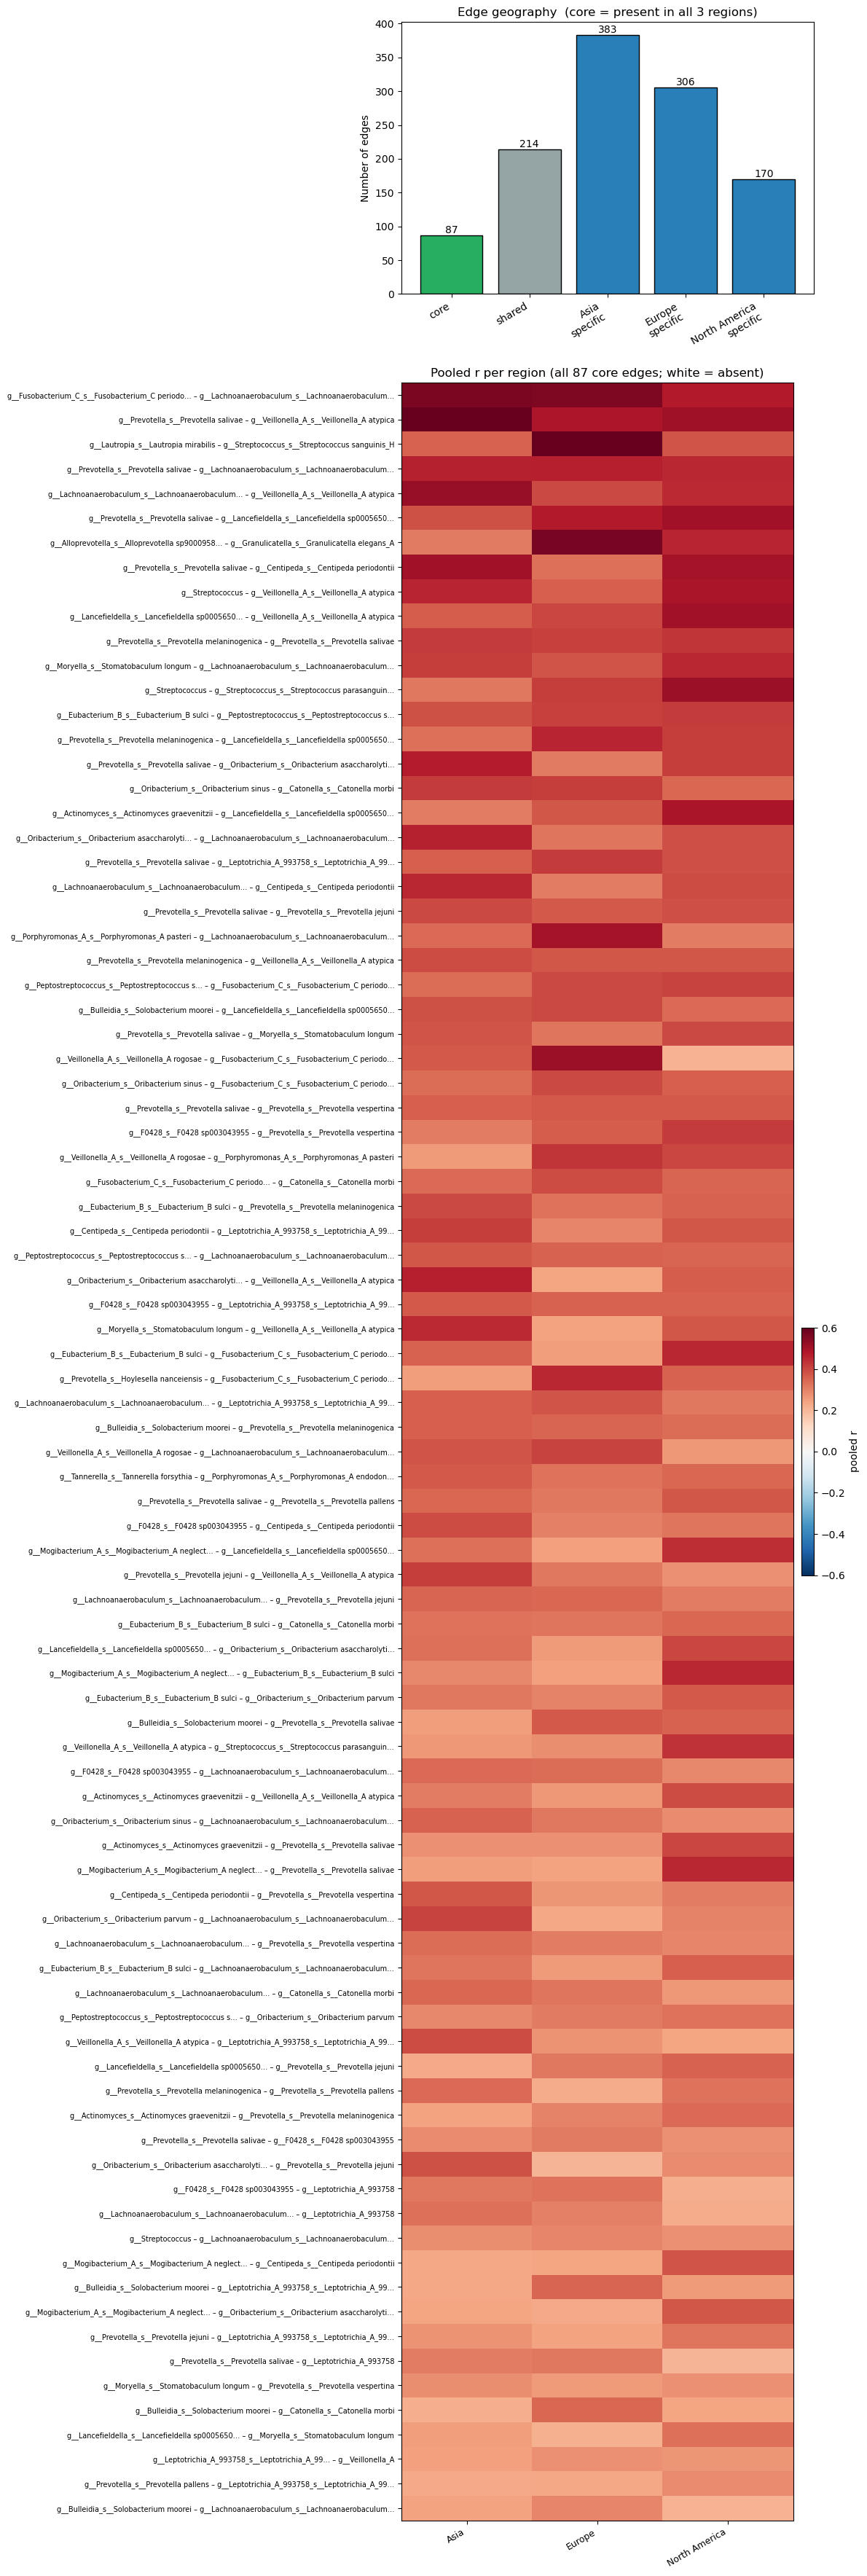

In [205]:
edges_df, info, fig = run(
    study_list, metadata_hc_saliva, fid_all,
    sparcc_dir="../data/network/sparcc_hc_saliva",
    min_studies_per_region=3,
    tax=tax, genus_col="Genus", species_col="Species",
    save_prefix="saliva_region",
)
edges_df